Zawartość:
1. Wczytanie danych i weryfikacja zgodności obrazów z metadanymi
2. Zmiany skórne a zdjęcia
3. Podział DermaMNIST-C od autorów i jego wada
4. Metadane: źródło zdjęć, wiek, lokalizacja
5. Prawie-duplikaty pod różnymi `lesion_id`
6. **Proponowany podział 70 / 10 / 20 na poziomie zmian, stratyfikowany po klasie**
7. Kontrola przecieku, statystyki nowego zbioru treningowego, zapis plików
8. Wnioski

DermaMNIST-C jest dostępny tylko w 28×28 i 224×224. Wersję 128×128 tworzymy sami, zmniejszając 224×224 (filtr Lanczosa).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors

SIZE = 128
SEED = 42
C_DIR = Path("data") / "dermamnist_c"
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
ZENODO = "https://zenodo.org/api/records/12739457/files/{}/content"
rng = np.random.default_rng(SEED)

CODES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
CODE2ID = {c: i for i, c in enumerate(CODES)}
SPLITS = ["train", "val", "test"]
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 100, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

def show_images(imgs, titles=None, ncols=8, size=1.5, suptitle=None):
    n = len(imgs); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * (1.22 if titles else 1.0)))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel(): ax.axis("off")
    for i, im in enumerate(imgs):
        if im is None: continue
        ax = axes.ravel()[i]; ax.imshow(im)
        if titles: ax.set_title(titles[i], fontsize=8, fontweight="normal", loc="center", color=INK2)
    if suptitle: fig.suptitle(suptitle, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout(h_pad=1.6)
    return fig

def class_table(labels_by_split):
    cnt = pd.DataFrame({s: np.bincount(l, minlength=7) for s, l in labels_by_split.items()}, index=CODES)
    return cnt, (cnt / cnt.sum() * 100).round(2)

## 1. Wczytanie danych i weryfikacja

In [2]:
def fetch(name):
    path = C_DIR / name
    if not path.exists():
        import urllib.request
        C_DIR.mkdir(parents=True, exist_ok=True)
        print("pobieranie", name); urllib.request.urlretrieve(ZENODO.format(name), path)
    return path

df = pd.read_csv(fetch("DermaMNIST-C.csv"))
z = np.load(fetch("dermamnist_corrected_224.npz"), allow_pickle=False)

# Obrazy w pliku .npz są ułożone w kolejności wierszy CSV w obrębie każdego podziału
meta = pd.concat([df[df["split"] == s] for s in SPLITS]).reset_index(drop=True)
meta = meta.rename(columns={"split": "split_c"})
y = np.concatenate([z[f"{s}_labels"].ravel() for s in SPLITS]).astype(int)
meta["label"] = meta["dx"].map(CODE2ID)
assert len(meta) == len(y) == 10015
assert (meta["label"].values == y).all(), "kolejność obrazów nie zgadza się z CSV"
print("Etykiety w .npz zgadzają się z CSV wiersz po wierszu we wszystkich trzech podziałach.")

X = np.empty((len(meta), SIZE, SIZE, 3), dtype=np.uint8)
i = 0
for s in SPLITS:
    for im in z[f"{s}_images"]:
        X[i] = np.asarray(Image.fromarray(im).resize((SIZE, SIZE), Image.LANCZOS)); i += 1
print("Obrazy:", X.shape, X.dtype, "| zdjęć:", len(meta), "| zmian skórnych:", meta["lesion_id"].nunique())
meta.head()

Etykiety w .npz zgadzają się z CSV wiersz po wierszu we wszystkich trzech podziałach.


Obrazy: (10015, 128, 128, 3) uint8 | zdjęć: 10015 | zmian skórnych: 7470


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,split_c,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,train,2
1,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern,train,2
2,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern,train,2
3,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern,train,2
4,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,vidir_modern,train,2


Dodatkowe sprawdzenie przypisania: zdjęcia o tym samym `lesion_id` powinny być do siebie bardziej podobne niż losowe pary zdjęć tej samej klasy.

In [3]:
LUM = np.array([0.299, 0.587, 0.114], dtype=np.float32)
G = np.concatenate([(X[k:k + 1000].astype(np.float32) @ LUM) for k in range(0, len(X), 1000)])
T = G.reshape(len(G), 16, SIZE // 16, 16, SIZE // 16).mean(axis=(2, 4)).reshape(len(G), -1)   # miniatury 16x16

def rmse(a, b): return np.sqrt(((T[a] - T[b]) ** 2).mean(axis=1))

idx_by_lesion = meta.groupby("lesion_id").indices
multi = [v for v in idx_by_lesion.values() if len(v) > 1]
a = np.array([v[0] for v in multi]); b = np.array([v[1] for v in multi])
same = rmse(a, b)
ra = rng.integers(0, len(meta), 20000); rb = rng.integers(0, len(meta), 20000)
keep = (y[ra] == y[rb]) & (meta["lesion_id"].values[ra] != meta["lesion_id"].values[rb])
rand = rmse(ra[keep], rb[keep])
print(f"Mediana RMSE miniatur: ta sama zmiana {np.median(same):.1f} (n = {len(same)}), "
      f"losowe pary tej samej klasy {np.median(rand):.1f} (n = {len(rand)})")

Mediana RMSE miniatur: ta sama zmiana 29.4 (n = 1956), losowe pary tej samej klasy 38.0 (n = 9571)


## 2. Zmiany skórne a zdjęcia

Ile zdjęć przypada na jedną zmianę i jak to wygląda w poszczególnych klasach. Każda zmiana z więcej niż jednym zdjęciem to potencjalny przeciek przy losowaniu podziału na poziomie zdjęć.

Zmian: 7470, zdjęć: 10015; zmiany z > 1 zdjęciem: 1956 (26.2%), obejmują 4501 zdjęć (44.9%)
Zmiany z niejednoznaczną diagnozą (różne dx w obrębie jednej zmiany): 0


,zdjęć,zmian,zdjęć na zmianę,% zmian z > 1 zdjęciem,% zdjęć w zmianach wielozdjęciowych
akiec,327,228,1.4,33.8,53.8
bcc,514,327,1.6,46.5,66.0
bkl,1099,727,1.5,39.5,60.0
df,115,73,1.6,46.6,66.1
mel,1113,614,1.8,62.5,79.3
nv,6705,5403,1.2,18.3,34.2
vasc,142,98,1.4,34.7,54.9


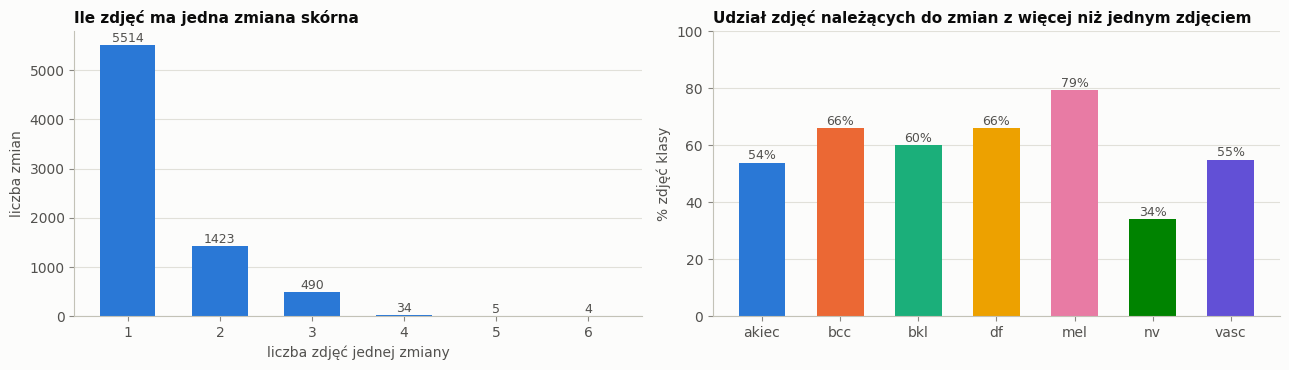

In [4]:
per_lesion = meta.groupby("lesion_id").agg(n=("image_id", "size"), label=("label", "first"), n_dx=("dx", "nunique"))
print(f"Zmian: {len(per_lesion)}, zdjęć: {len(meta)}; zmiany z > 1 zdjęciem: {(per_lesion.n > 1).sum()} "
      f"({(per_lesion.n > 1).mean():.1%}), obejmują {per_lesion.n[per_lesion.n > 1].sum()} zdjęć "
      f"({per_lesion.n[per_lesion.n > 1].sum() / len(meta):.1%})")
print("Zmiany z niejednoznaczną diagnozą (różne dx w obrębie jednej zmiany):", int((per_lesion.n_dx > 1).sum()))

les_tab = pd.DataFrame({
    "zdjęć": np.bincount(y, minlength=7),
    "zmian": np.bincount(per_lesion.label, minlength=7),
}, index=CODES)
les_tab["zdjęć na zmianę"] = (les_tab["zdjęć"] / les_tab["zmian"]).round(2)
les_tab["% zmian z > 1 zdjęciem"] = [100 * (per_lesion.n[per_lesion.label == k] > 1).mean() for k in range(7)]
les_tab["% zdjęć w zmianach wielozdjęciowych"] = [
    100 * per_lesion.n[(per_lesion.label == k) & (per_lesion.n > 1)].sum() / les_tab["zdjęć"].iloc[k] for k in range(7)]
display(les_tab.round(1))

vc = per_lesion.n.value_counts().sort_index()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.bar(vc.index.astype(str), vc.values, color="#2a78d6", width=0.6)
for xi, v in enumerate(vc.values): ax1.text(xi, v + 60, str(v), ha="center", fontsize=9, color=INK2)
ax1.set_xlabel("liczba zdjęć jednej zmiany"); ax1.set_ylabel("liczba zmian"); ax1.grid(axis="x", visible=False)
ax1.set_title("Ile zdjęć ma jedna zmiana skórna")
ax2.bar(CODES, les_tab["% zdjęć w zmianach wielozdjęciowych"], color=CLASS_COLORS, width=0.6)
for xi, v in enumerate(les_tab["% zdjęć w zmianach wielozdjęciowych"]): ax2.text(xi, v + 1.2, f"{v:.0f}%", ha="center", fontsize=9, color=INK2)
ax2.set_ylabel("% zdjęć klasy"); ax2.set_ylim(0, 100); ax2.grid(axis="x", visible=False)
ax2.set_title("Udział zdjęć należących do zmian z więcej niż jednym zdjęciem")
fig.tight_layout(); save(fig, "c01_zmiany_a_zdjecia"); plt.show()

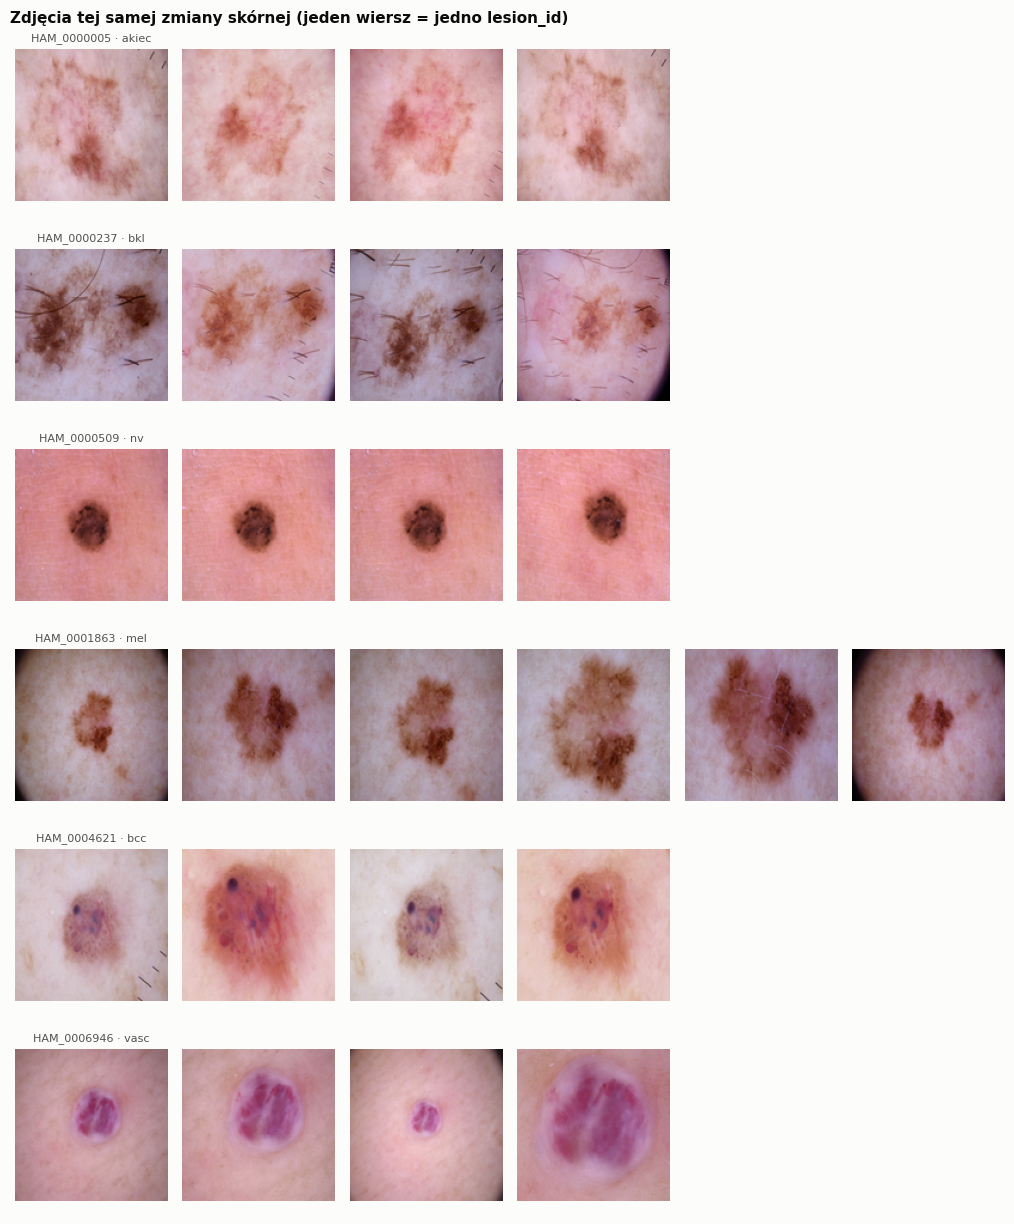

In [5]:
# Przykłady: jedna zmiana = jeden wiersz
ex = per_lesion[per_lesion.n >= 4].groupby("label").head(1).index[:6]
imgs, titles = [], []
for lid in ex:
    ids = idx_by_lesion[lid][:6]
    for k in range(6):
        imgs.append(X[ids[k]] if k < len(ids) else None)
        titles.append(f"{lid} · {CODES[y[ids[0]]]}" if k == 0 else "")
fig = show_images(imgs, titles, ncols=6, size=1.7, suptitle="Zdjęcia tej samej zmiany skórnej (jeden wiersz = jedno lesion_id)")
save(fig, "c02_ta_sama_zmiana"); plt.show()

## 3. Podział DermaMNIST-C od autorów

Autorzy naprawili przeciek, przenosząc do zbioru treningowego te zdjęcia z val/test, których zmiana miała już zdjęcie w train. Porównanie liczności z oficjalnym DermaMNIST pokazuje skalę przecieku w oryginale.

In [6]:
# Liczności oficjalnego DermaMNIST (z notebooka 01_eda)
ORIG = pd.DataFrame({"train": [228, 359, 769, 80, 779, 4693, 99], "val": [33, 52, 110, 12, 111, 671, 14],
                     "test": [66, 103, 220, 23, 223, 1341, 29]}, index=CODES)
cnt_c, share_c = class_table({s: y[meta["split_c"].values == s] for s in SPLITS})

g = meta.groupby("lesion_id")["split_c"].nunique()
print("DermaMNIST-C: zmiany obecne w więcej niż jednym podziale:", int((g > 1).sum()))
moved = ORIG.sum() - cnt_c.sum()
print(f"Rozmiary: oficjalny {ORIG.sum().tolist()}  →  DermaMNIST-C {cnt_c.sum().tolist()}")
print(f"Z testu ubyło {moved['test']} zdjęć ({moved['test'] / ORIG['test'].sum():.1%} oficjalnego testu), "
      f"z walidacji {moved['val']} ({moved['val'] / ORIG['val'].sum():.1%}); train urósł o {-moved['train']}.")
pd.concat([cnt_c.add_prefix("n "), share_c.add_prefix("% ")], axis=1)

DermaMNIST-C: zmiany obecne w więcej niż jednym podziale: 0
Rozmiary: oficjalny [7007, 1003, 2005]  →  DermaMNIST-C [8215, 573, 1227]
Z testu ubyło 778 zdjęć (38.8% oficjalnego testu), z walidacji 430 (42.9%); train urósł o 1208.


,n train,n val,n test,% train,% val,% test
akiec,273,19,35,3.32,3.32,2.85
bcc,448,22,44,5.45,3.84,3.59
bkl,944,50,105,11.49,8.73,8.56
df,102,5,8,1.24,0.87,0.65
mel,1021,22,70,12.43,3.84,5.70
nv,5309,448,948,64.63,78.18,77.26
vasc,118,7,17,1.44,1.22,1.39


Skoro przeniesienia odbywały się tylko z val/test do train, to ubytek testu i walidacji jest równy liczbie zdjęć, których zmiana miała w oficjalnym podziale zdjęcie w zbiorze treningowym.

**Wada tego podziału:** przenoszono zdjęcia bez pilnowania proporcji klas, więc val i test przestały być stratyfikowane (patrz udział `mel` w tabeli), a same zbiory są małe — w walidacji zostaje po kilka zdjęć klas rzadkich.

## 4. Metadane: źródło zdjęć, wiek, lokalizacja

HAM10000 składa się z czterech podzbiorów zebranych różnym sprzętem. Jeśli skład klas różni się między źródłami, model może rozpoznawać źródło (styl zdjęcia) zamiast zmiany.

dx,akiec,bcc,bkl,df,mel,nv,vasc,razem
dataset,,,,,,,,
rosendahl,295,296,490,30,342,803,3,2259
vidir_modern,32,211,475,51,680,1832,82,3363
vidir_molemax,0,2,124,30,24,3720,54,3954
vienna_dias,0,5,10,4,67,350,3,439


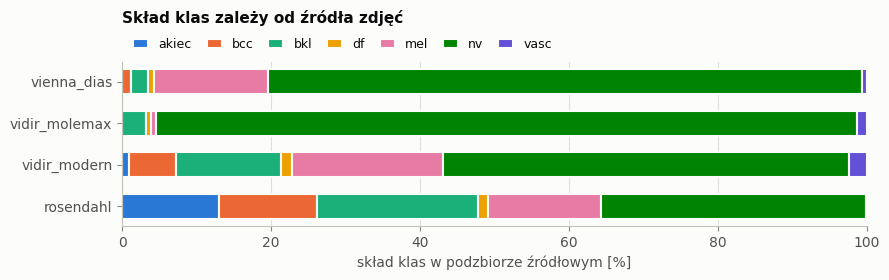

Sposób potwierdzenia diagnozy (dx_type) w klasach [%]:


dx_type,confocal,consensus,follow_up,histo
dx,,,,
akiec,0.0,0.0,0.0,100.0
bcc,0.0,0.0,0.0,100.0
bkl,6.3,24.0,0.0,69.7
df,0.0,52.2,0.0,47.8
mel,0.0,0.0,0.0,100.0
nv,0.0,7.5,55.2,37.3
vasc,0.0,52.8,0.0,47.2


In [7]:
src = pd.crosstab(meta["dataset"], meta["dx"])[CODES]
src_pct = (src.T / src.sum(axis=1)).T * 100
display(src.assign(razem=src.sum(axis=1)))

fig, ax = plt.subplots(figsize=(9, 2.9))
left = np.zeros(len(src_pct))
for k, c in enumerate(CODES):
    ax.barh(src_pct.index, src_pct[c], left=left, color=CLASS_COLORS[k], label=c, height=0.6, edgecolor=SURFACE, linewidth=1.5)
    left += src_pct[c].values
ax.set_xlim(0, 100); ax.set_xlabel("skład klas w podzbiorze źródłowym [%]"); ax.grid(axis="y", visible=False)
ax.legend(ncol=7, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9, handlelength=1.2, columnspacing=1.2)
ax.set_title("Skład klas zależy od źródła zdjęć", pad=28)
fig.tight_layout(); save(fig, "c03_zrodlo_a_klasa"); plt.show()

print("Sposób potwierdzenia diagnozy (dx_type) w klasach [%]:")
display((pd.crosstab(meta["dx"], meta["dx_type"], normalize="index") * 100).round(1).loc[CODES])

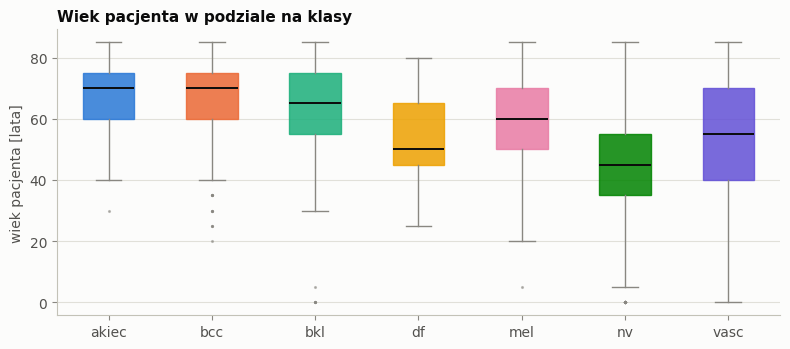

Braki danych: wiek 57 zdjęć; płeć 'unknown' 57; lokalizacja 'unknown' 234
Płeć [%]: {'male': 54.0, 'female': 45.5, 'unknown': 0.6}
Najczęstsze lokalizacje [%]: {'back': 21.9, 'lower extremity': 20.7, 'trunk': 14.0, 'upper extremity': 11.2, 'abdomen': 10.2, 'face': 7.4}


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ages = [meta["age"][(y == k) & meta["age"].notna()].values for k in range(7)]
bp = ax.boxplot(ages, patch_artist=True, widths=0.5, medianprops=dict(color=INK, lw=1.4),
                flierprops=dict(marker=".", ms=2.5, mec=MUTED, mfc=MUTED, alpha=0.5),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, col in zip(bp["boxes"], CLASS_COLORS):
    patch.set_facecolor(col); patch.set_edgecolor(col); patch.set_alpha(0.85)
ax.set_xticks(range(1, 8)); ax.set_xticklabels(CODES); ax.set_ylabel("wiek pacjenta [lata]"); ax.grid(axis="x", visible=False)
ax.set_title("Wiek pacjenta w podziale na klasy")
fig.tight_layout(); save(fig, "c04_wiek"); plt.show()

print(f"Braki danych: wiek {int(meta['age'].isna().sum())} zdjęć; płeć 'unknown' {int((meta['sex'] == 'unknown').sum())}; "
      f"lokalizacja 'unknown' {int((meta['localization'] == 'unknown').sum())}")
print("Płeć [%]:", (meta["sex"].value_counts(normalize=True) * 100).round(1).to_dict())
print("Najczęstsze lokalizacje [%]:", (meta["localization"].value_counts(normalize=True) * 100).round(1).head(6).to_dict())

## 5. Prawie-duplikaty pod różnymi `lesion_id`

Autorzy DermaMNIST-C zgłaszają, że w HAM10000 zdarzają się niemal identyczne zdjęcia opisane różnymi `lesion_id`. Szukamy ich tak jak w pierwszej EDA (miniatury 16×16 w skali szarości, RMSE w skali 0–255). Pary poniżej progu łączymy w jedną grupę, żeby na pewno trafiły do tego samego podziału. Łączenie jest bezpieczne nawet przy fałszywym trafieniu — dwie różne zmiany po prostu lądują razem.

,par,to samo lesion_id,różne lesion_id,różne lesion_id i różna klasa
próg RMSE,,,,
3,14,13,1,0
4,32,31,1,0
5,45,40,5,3
6,81,49,32,6
7,269,77,192,65


Pary o różnych lesion_id poniżej progu 5.0: 5


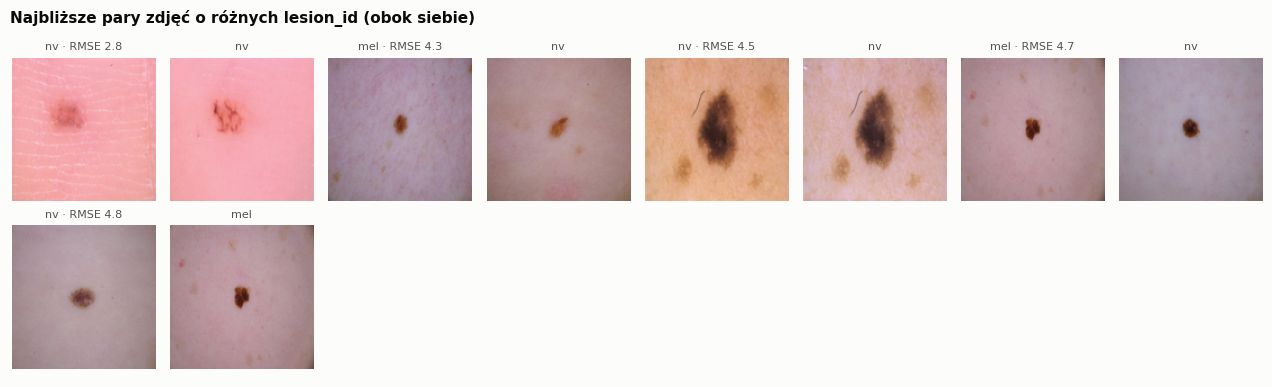

In [9]:
DUP_THR = 5.0
dist, nbr = NearestNeighbors(n_neighbors=6).fit(T).kneighbors(T)
dist = dist / np.sqrt(T.shape[1])
les = meta["lesion_id"].values
pairs = [(a_, int(nbr[a_, k]), dist[a_, k]) for a_ in range(len(T)) for k in range(1, 6) if a_ < nbr[a_, k]]
P = pd.DataFrame(pairs, columns=["a", "b", "rmse"])
P["ta sama zmiana"] = les[P.a] == les[P.b]; P["ta sama klasa"] = y[P.a] == y[P.b]
rows = []
for t in [3, 4, 5, 6, 7]:
    q = P[P.rmse < t]
    rows.append({"próg RMSE": t, "par": len(q), "to samo lesion_id": int(q["ta sama zmiana"].sum()),
                 "różne lesion_id": int((~q["ta sama zmiana"]).sum()),
                 "różne lesion_id i różna klasa": int((~q["ta sama zmiana"] & ~q["ta sama klasa"]).sum())})
display(pd.DataFrame(rows).set_index("próg RMSE"))

cross = P[(~P["ta sama zmiana"]) & (P.rmse < DUP_THR)].sort_values("rmse").reset_index(drop=True)
print(f"Pary o różnych lesion_id poniżej progu {DUP_THR}: {len(cross)}")
imgs, titles = [], []
for _, r in cross.head(8).iterrows():
    imgs += [X[int(r.a)], X[int(r.b)]]
    titles += [f"{CODES[y[int(r.a)]]} · RMSE {r.rmse:.1f}", CODES[y[int(r.b)]]]
if imgs:
    fig = show_images(imgs, titles, ncols=8, size=1.6, suptitle="Najbliższe pary zdjęć o różnych lesion_id (obok siebie)")
    save(fig, "c05_pary_rozne_lesion_id"); plt.show()

In [10]:
# Grupy = lesion_id, dodatkowo sklejone parami prawie-duplikatów (składowe spójne grafu)
les_codes, les_uniques = pd.factorize(meta["lesion_id"])
n = len(les_uniques)
ea = les_codes[cross.a.values.astype(int)]; eb = les_codes[cross.b.values.astype(int)]
graph = coo_matrix((np.ones(len(ea)), (ea, eb)), shape=(n, n))
n_groups, comp = connected_components(graph, directed=False)
meta["group_id"] = comp[les_codes]
print(f"Zmian (lesion_id): {n}  →  grup do podziału: {n_groups} (sklejono {n - n_groups})")

Zmian (lesion_id): 7470  →  grup do podziału: 7465 (sklejono 5)


## 6. Proponowany podział: 70 / 10 / 20 na poziomie zmian, stratyfikowany po klasie

Założenia:
- **wszystkie zdjęcia jednej grupy (zmiany) trafiają do jednego podziału** — brak przecieku z definicji,
- **proporcje klas są zachowane** w train / val / test (stratyfikacja),
- proporcje rozmiarów jak w oficjalnym DermaMNIST (70 / 10 / 20), żadne zdjęcie nie jest usuwane.

Metoda: `StratifiedGroupKFold` z 10 foldami; 2 foldy → test, 1 → val, 7 → train. Ponieważ klasy rzadkie mają po kilkadziesiąt zmian, wynik zależy od ziarna losowości — sprawdzamy 30 ziaren i bierzemy to, przy którym liczność żadnej klasy w val ani test nie odbiega mocno od oczekiwanej. Numer folda zapisujemy, więc te same foldy nadają się też do walidacji krzyżowej.

In [11]:
groups = meta["group_id"].values
global_share = np.bincount(y, minlength=7) / len(y)

def make_split(seed):
    fold = np.empty(len(y), dtype=int)
    sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for f, (_, te) in enumerate(sgkf.split(np.zeros(len(y)), y, groups)): fold[te] = f
    split = np.where(fold <= 1, "test", np.where(fold == 2, "val", "train"))
    dev = max(np.abs(np.bincount(y[split == s], minlength=7) / (split == s).sum() / global_share - 1).max() for s in ["val", "test"])
    return fold, split, dev

results = {seed: make_split(seed) for seed in range(30)}
best = min(results, key=lambda s: results[s][2])
fold, split_new, dev = results[best]
meta["fold"] = fold; meta["split_new"] = split_new
devs = np.array([r[2] for r in results.values()])
print(f"Wybrane ziarno: {best} — największe względne odchylenie udziału klasy w val/test: {dev:.1%} "
      f"(wśród 30 ziaren: mediana {np.median(devs):.1%}, najgorsze {devs.max():.1%})")

leak = meta.groupby("group_id")["split_new"].nunique()
assert (leak == 1).all()
print("Grupy obecne w więcej niż jednym podziale:", int((leak > 1).sum()))
cnt_n, share_n = class_table({s: y[split_new == s] for s in SPLITS})
print("Rozmiary:", cnt_n.sum().to_dict(), "| udział:", (cnt_n.sum() / len(y)).round(3).to_dict())
print("Zmian (lesion_id) w podziałach:", meta.groupby("split_new")["lesion_id"].nunique().reindex(SPLITS).to_dict())
pd.concat([cnt_n.add_prefix("n "), share_n.add_prefix("% ")], axis=1)

Wybrane ziarno: 5 — największe względne odchylenie udziału klasy w val/test: 8.4% (wśród 30 ziaren: mediana 24.7%, najgorsze 69.2%)
Grupy obecne w więcej niż jednym podziale: 0
Rozmiary: {'train': 7023, 'val': 1001, 'test': 1991} | udział: {'train': 0.701, 'val': 0.1, 'test': 0.199}
Zmian (lesion_id) w podziałach: {'train': 5228, 'val': 747, 'test': 1495}


,n train,n val,n test,% train,% val,% test
akiec,234,31,62,3.33,3.10,3.11
bcc,365,54,95,5.20,5.39,4.77
bkl,765,105,229,10.89,10.49,11.50
df,80,11,24,1.14,1.10,1.21
mel,779,109,225,11.09,10.89,11.30
nv,4697,678,1330,66.88,67.73,66.80
vasc,103,13,26,1.47,1.30,1.31


### Porównanie trzech podziałów

Wykres pokazuje, o ile udział każdej klasy w val i test odbiega od jej udziału w całym zbiorze (1,0 = idealna stratyfikacja).

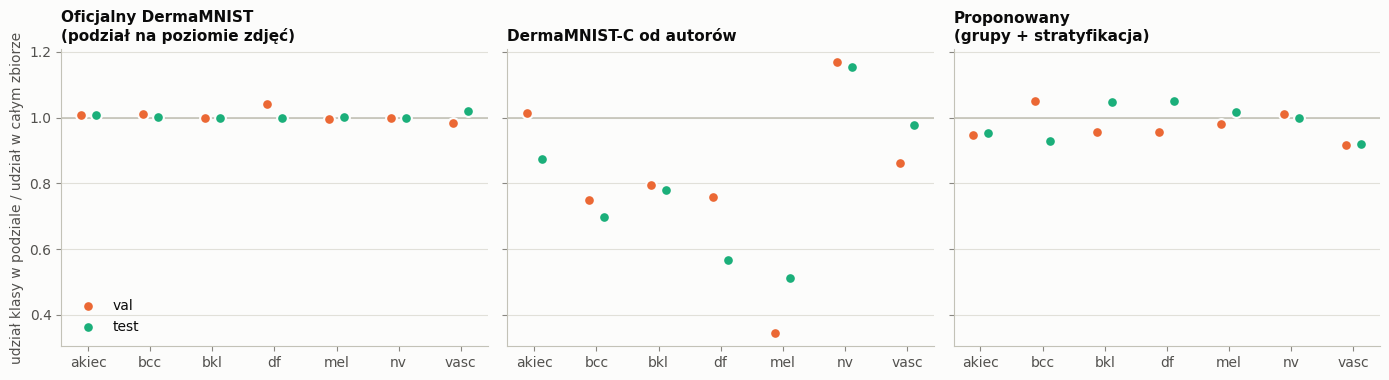

,train / val / test,przeciek zmian między podziałami,najmniejsza klasa w val,najmniejsza klasa w test,udział mel w val [%],udział mel w test [%]
Oficjalny DermaMNIST (podział na poziomie zdjęć),7007 / 1003 / 2005,tak — 778 zdjęć testu i 430 walidacji,df (12),df (23),11.1,11.1
DermaMNIST-C od autorów,8215 / 573 / 1227,nie,df (5),df (8),3.8,5.7
Proponowany (grupy + stratyfikacja),7023 / 1001 / 1991,nie,df (11),df (24),10.9,11.3


In [12]:
schemes = {"Oficjalny DermaMNIST\n(podział na poziomie zdjęć)": ORIG,
           "DermaMNIST-C od autorów": cnt_c,
           "Proponowany\n(grupy + stratyfikacja)": cnt_n}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, (name, cnt) in zip(axes, schemes.items()):
    tot = cnt.sum(axis=1) / cnt.values.sum()
    ax.axhline(1.0, color=AXIS, lw=1.2)
    for s, off in [("val", -0.12), ("test", 0.12)]:
        ratio = (cnt[s] / cnt[s].sum()) / tot
        ax.scatter(np.arange(7) + off, ratio, s=60, color=SPLIT_COLORS[s], label=s, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.set_xticks(np.arange(7)); ax.set_xticklabels(CODES); ax.set_title(name); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("udział klasy w podziale / udział w całym zbiorze")
axes[0].legend(frameon=False, loc="lower left")
fig.tight_layout(); save(fig, "c06_porownanie_podzialow"); plt.show()

summary = pd.DataFrame({
    "train / val / test": {k.replace("\n", " "): " / ".join(map(str, c.sum().tolist())) for k, c in schemes.items()},
    "przeciek zmian między podziałami": dict(zip([k.replace("\n", " ") for k in schemes],
        [f"tak — {moved['test']} zdjęć testu i {moved['val']} walidacji", "nie", "nie"])),
    "najmniejsza klasa w val": {k.replace("\n", " "): f"{c['val'].idxmin()} ({c['val'].min()})" for k, c in schemes.items()},
    "najmniejsza klasa w test": {k.replace("\n", " "): f"{c['test'].idxmin()} ({c['test'].min()})" for k, c in schemes.items()},
    "udział mel w val [%]": {k.replace("\n", " "): round(100 * c.loc["mel", "val"] / c["val"].sum(), 1) for k, c in schemes.items()},
    "udział mel w test [%]": {k.replace("\n", " "): round(100 * c.loc["mel", "test"] / c["test"].sum(), 1) for k, c in schemes.items()},
})
summary

## 7. Kontrola, statystyki nowego zbioru treningowego i zapis

### 7.1 Kontrola przecieku miniaturami

Ten sam test co w pierwszej EDA: dla każdego zdjęcia z val/test najbliższe zdjęcie w train.

In [13]:
tr = np.where(split_new == "train")[0]
nn_tr = NearestNeighbors(n_neighbors=1).fit(T[tr])
for s in ["val", "test"]:
    ii = np.where(split_new == s)[0]
    d = nn_tr.kneighbors(T[ii])[0].ravel() / np.sqrt(T.shape[1])
    print(f"{s}: RMSE do najbliższego zdjęcia w train — mediana {np.median(d):.1f}; < 3: {(d < 3).sum()}, < 5: {(d < 5).sum()}, < 6: {(d < 6).sum()}  (na {len(ii)})")
print("Dla porównania oficjalny DermaMNIST (128×128): test < 5: 12, val < 5: 8.")

val: RMSE do najbliższego zdjęcia w train — mediana 13.1; < 3: 0, < 5: 0, < 6: 4  (na 1001)
test: RMSE do najbliższego zdjęcia w train — mediana 12.8; < 3: 0, < 5: 0, < 6: 8  (na 1991)
Dla porównania oficjalny DermaMNIST (128×128): test < 5: 12, val < 5: 8.


### 7.2 Statystyki do normalizacji, wagi klas i punkt odniesienia dla nowego podziału

In [14]:
Xtr = X[tr]; ytr = y[tr]
px = Xtr.reshape(-1, 3)
s1 = np.zeros(3); s2 = np.zeros(3)
for k in range(0, len(px), 5_000_000):
    c = px[k:k + 5_000_000].astype(np.float64) / 255.0
    s1 += c.sum(axis=0); s2 += (c ** 2).sum(axis=0)
MEAN = s1 / len(px); STD = np.sqrt(s2 / len(px) - MEAN ** 2)
print("Normalizacja (nowy train, skala 0-1):  mean =", MEAN.round(4).tolist(), " std =", STD.round(4).tolist())

n_k = np.bincount(ytr, minlength=7)
display(pd.DataFrame({"n_train": n_k, "waga": (n_k.sum() / (7 * n_k)).round(3)}, index=CODES))

major = int(n_k.argmax()); rows = []
for s in ["val", "test"]:
    yt = y[split_new == s]; pred = np.full_like(yt, major)
    rows.append({"podział": s, "accuracy": accuracy_score(yt, pred), "balanced accuracy": balanced_accuracy_score(yt, pred),
                 "macro-F1": f1_score(yt, pred, average="macro", zero_division=0)})
print(f"Punkt odniesienia „zawsze {CODES[major]}”:")
pd.DataFrame(rows).set_index("podział").round(3)

Normalizacja (nowy train, skala 0-1):  mean = [0.7644, 0.5468, 0.5715]  std = [0.1402, 0.1523, 0.1694]


,n_train,waga
akiec,234,4.288
bcc,365,2.749
bkl,765,1.311
df,80,12.541
mel,779,1.288
nv,4697,0.214
vasc,103,9.741


Punkt odniesienia „zawsze nv”:


,accuracy,balanced accuracy,macro-F1
podział,,,
val,0.677,0.143,0.115
test,0.668,0.143,0.114


### 7.3 Zapis

- `DermaMNIST-C_podzial_lesion.csv` — metadane + `group_id`, `fold` (0–9), `split_new`, `npz_index` (pozycja zdjęcia w odpowiedniej tablicy pliku `.npz`),
- `dermamnist_c_lesion_split_128.npz` — obrazy 128×128 i etykiety w formacie MedMNIST (`train_images`, `train_labels`, ...).

In [15]:
meta["npz_index"] = -1
arrays = {}
for s in SPLITS:
    ii = np.where(split_new == s)[0]
    meta.loc[ii, "npz_index"] = np.arange(len(ii))
    arrays[f"{s}_images"] = X[ii]; arrays[f"{s}_labels"] = y[ii].astype(np.uint8).reshape(-1, 1)
csv_path = C_DIR / "DermaMNIST-C_podzial_lesion.csv"
npz_path = C_DIR / f"dermamnist_c_lesion_split_{SIZE}.npz"
meta.to_csv(csv_path, index=False)
np.savez_compressed(npz_path, **arrays)
print("zapisano:", csv_path, "|", npz_path, f"({npz_path.stat().st_size / 1e6:.0f} MB)")
for k, v in arrays.items(): print(f"  {k:13s} {v.shape}")

zapisano: data\dermamnist_c\DermaMNIST-C_podzial_lesion.csv | data\dermamnist_c\dermamnist_c_lesion_split_128.npz (386 MB)
  train_images  (7023, 128, 128, 3)
  train_labels  (7023, 1)
  val_images    (1001, 128, 128, 3)
  val_labels    (1001, 1)
  test_images   (1991, 128, 128, 3)
  test_labels   (1991, 1)
